In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#  AI Interview Platform — CV Module
## Notebook 01: Data Audit & Cleaning

**الهدف:** نفهم داتا الـ CVs ونظّفها ونجهّزها للمراحل الجاية.

**الخطوات:** الإعداد، فحص الجودة، التوزيعات، التنضيف، استكشاف الفولدر، الحفظ.

In [ ]:
!pip install -q pdfplumber python-docx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 573.6 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 106.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)


CSV_PATH = "/Resume.csv"
SEED = 42

In [ ]:
## تحميل الملف
def load_csv(path):
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not read {path} with common encodings")

df = load_csv("/Resume.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head(3)

Shape: (2484, 4)
Columns: ['ID', 'Resume_str', 'Resume_html', 'Category']


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR Summary Dedicated Customer Service Manag...,"<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsectio...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS Summary Versatile media professional with background in Communic...","<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsectio...",HR
2,33176873,"HR DIRECTOR Summary Over 20 years experience in recruiting, 15 plus years in Human Resources E...","<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsectio...",HR


## Part 2: Selecting Columns & Data Quality Check

الأعمدة اللي عندنا:
- **Resume_str**: نص الـ CV العادي ← ده اللي هنشتغل عليه
- **Category**: المجال الوظيفي (HR, IT...) ← ده الـ label
- **ID**: رقم الـ CV
- **Resume_html**: نفس الـ CV بس بكود HTML ← مش محتاجينه
- **index**: رقم الصف ← مش محتاجينه

بعد كده هنفحص: قيم ناقصة، تكرار، وأطوال الـ CVs.

In [ ]:
df = df[["ID", "Category", "Resume_str"]].copy()
df = df.rename(columns={"Category": "category", "Resume_str": "resume_raw"})

print("Shape:", df.shape)
df.head(3)

Shape: (2484, 3)


,ID,category,resume_raw
0,16852973,HR,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR Summary Dedicated Customer Service Manag...
1,22323967,HR,"HR SPECIALIST, US HR OPERATIONS Summary Versatile media professional with background in Communic..."
2,33176873,HR,"HR DIRECTOR Summary Over 20 years experience in recruiting, 15 plus years in Human Resources E..."


In [ ]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate CV texts:", df["resume_raw"].duplicated().sum())

df["n_words"] = df["resume_raw"].fillna("").str.split().str.len()
print("\nWords per CV:")
print(df["n_words"].describe().round(0))

print("\nCVs under 50 words:", (df["n_words"] < 50).sum())

Missing values:
ID            0
category      0
resume_raw    0
dtype: int64

Duplicate CV texts: 2

Words per CV:
count    2484.0
mean      811.0
std       371.0
min         0.0
25%       651.0
50%       757.0
75%       933.0
max      5190.0
Name: n_words, dtype: float64

CVs under 50 words: 1


In [ ]:
print("Number of categories:", df["category"].nunique())
print()
print(df["category"].value_counts())

Number of categories: 24

category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


## Part 3: Visualizing the Data & Inspecting Problem Rows

هنعمل 3 حاجات:
1. نرسم توزيع الفئات (هل الداتا متوازنة؟)
2. نرسم توزيع أطوال الـ CVs
3. نشوف بعينينا الصفوف المشكلة (الفاضي والمكرر) قبل ما نمسحها

category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22

Biggest / smallest class ratio: 5.5x


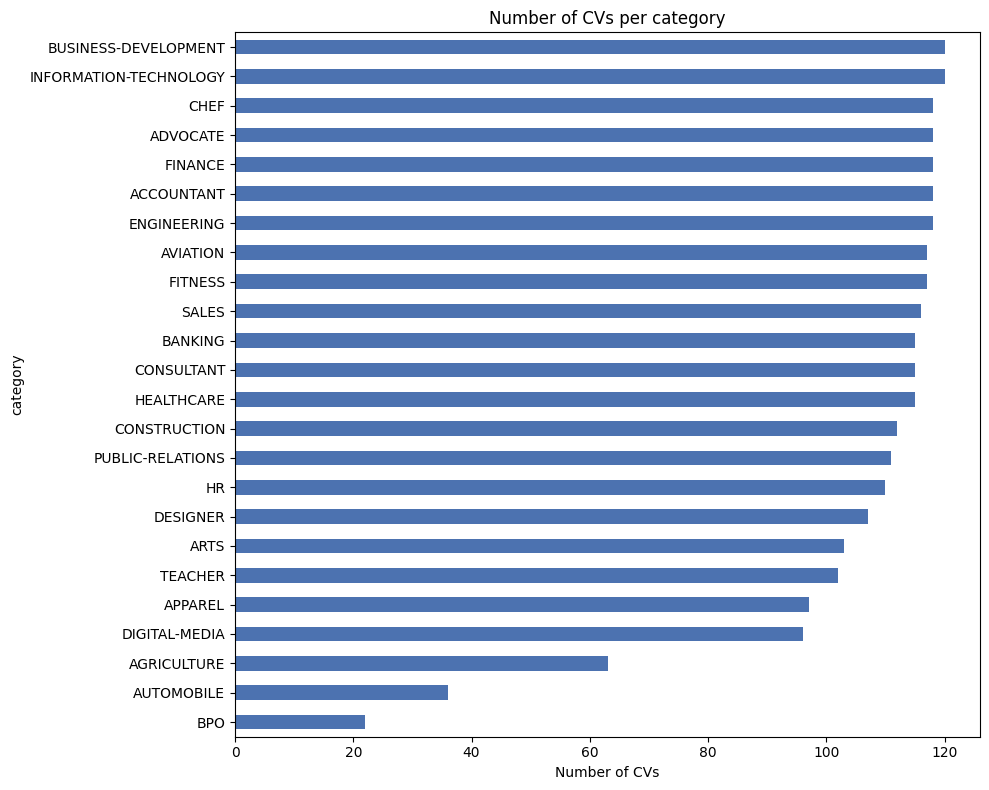

In [ ]:
counts = df["category"].value_counts()
print(counts.to_string())
print(f"\nBiggest / smallest class ratio: {counts.max() / counts.min():.1f}x")

counts.sort_values().plot(kind="barh", color="#4C72B0", figsize=(10, 8))
plt.title("Number of CVs per category")
plt.xlabel("Number of CVs")
plt.tight_layout()
plt.show()

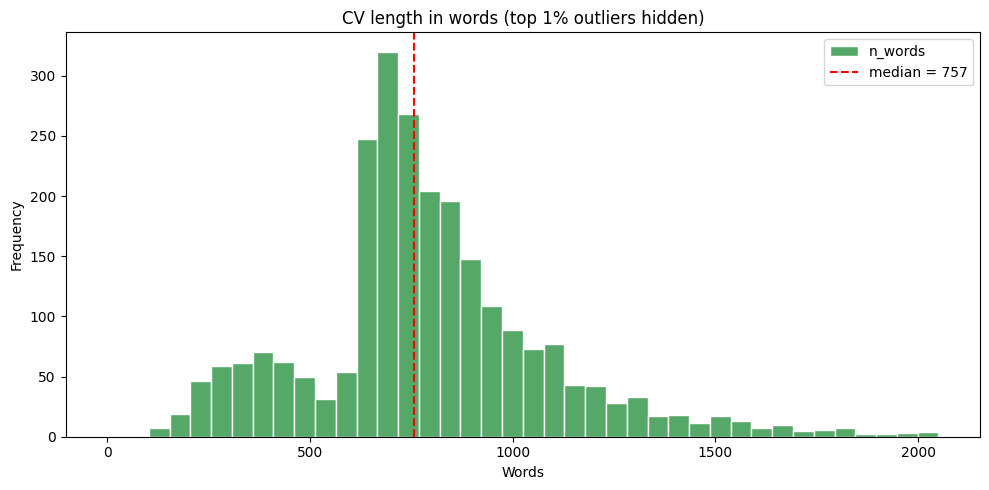

99th percentile: 2052


In [ ]:
limit = df["n_words"].quantile(0.99)

df[df["n_words"] <= limit]["n_words"].plot(
    kind="hist", bins=40, color="#55A868", edgecolor="white"
)
plt.axvline(df["n_words"].median(), color="red", linestyle="--",
            label=f"median = {df['n_words'].median():.0f}")
plt.title("CV length in words (top 1% outliers hidden)")
plt.xlabel("Words")
plt.legend()
plt.tight_layout()
plt.show()

print("99th percentile:", int(limit))

In [ ]:
print("=== Empty / very short CVs ===")
print(df[df["n_words"] < 50][["ID", "category", "n_words"]])

print("\n=== Duplicate CVs ===")
dups = df[df["resume_raw"].duplicated(keep=False)].sort_values("resume_raw")
print(dups[["ID", "category", "n_words"]])

=== Empty / very short CVs ===
           ID              category  n_words
656  12632728  BUSINESS-DEVELOPMENT        0

=== Duplicate CVs ===
            ID  category  n_words
1490  19147603   FINANCE      650
1509  28398216   FINANCE      650
2444  16850314  AVIATION      681
2483  37473139  AVIATION      681


## Part 4: Cleaning the Data

هنعمل 4 حاجات:
1. نمسح الـ CV الفاضي والمكرر
2. ننضف النصوص (روابط، إيميلات، تليفونات، كلمات الإخفاء المتكررة، مسافات زيادة)
3. نقارن قبل وبعد
4. نحفظ النسخة النضيفة

**ملاحظة:** بنسيب حالة الحروف (Capital/Small) زي ما هي، لأن الـ LLM هيستفيد منها في المرحلة الجاية.

In [ ]:
before = len(df)

df = df[df["n_words"] >= 50]
df = df.drop_duplicates(subset="resume_raw", keep="first")
df = df.reset_index(drop=True)

print(f"Rows: {before} -> {len(df)}  (removed {before - len(df)})")

Rows: 2484 -> 2481  (removed 3)


In [ ]:
EMAIL_RE = re.compile(r"[\w\.\-+]+@[\w\.\-]+\.\w+")
URL_RE = re.compile(r"(https?://\S+|www\.\S+)")
PHONE_RE = re.compile(r"(?<!\w)(\+?\d{1,3}[-.\s])?\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}(?!\w)")
LOC_RE = re.compile(r"\bCity\s*,\s*State\b")
COMP_RE = re.compile(r"Company Name\s*[－—–\-]*")
CTRL_RE = re.compile(r"[\x00-\x08\x0b-\x1f\x7f]")

def clean_text(text):
    text = str(text)
    for rx in (URL_RE, EMAIL_RE, PHONE_RE, LOC_RE, COMP_RE, CTRL_RE):
        text = rx.sub(" ", text)
    text = text.replace("－", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\s+,", ",", text)
    text = re.sub(r"\s*\n\s*", "\n", text)
    return text.strip()

df["resume_clean"] = df["resume_raw"].apply(clean_text)
df["n_words_clean"] = df["resume_clean"].str.split().str.len()
print("Done. Average words:", int(df["n_words"].mean()), "->", int(df["n_words_clean"].mean()))

Done. Average words: 811 -> 779


In [ ]:
sample = df.sample(1, random_state=SEED).iloc[0]

print("CATEGORY:", sample["category"])
print("\n--- BEFORE (first 500 chars) ---")
print(sample["resume_raw"][:500])
print("\n--- AFTER (first 500 chars) ---")
print(sample["resume_clean"][:500])

CATEGORY: INFORMATION-TECHNOLOGY

--- BEFORE (first 500 chars) ---
         INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)       Summary     I am obsessed with technology. It's power to change everything. Technology fuels my passion and commitment to helping organizations do what they set out to. When I engage, I bring fresh ideas that help your team galvanize performance. Refine your strategy. Spark new energy. 
The future—and how we get there—depends on those who build, connect, create and transform our world.  Accomplished with over 10 years of information

--- AFTER (first 500 chars) ---
INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX) Summary I am obsessed with technology. It's power to change everything. Technology fuels my passion and commitment to helping organizations do what they set out to. When I engage, I bring fresh ideas that help your team galvanize performance. Refine your strategy. Spark new energy.
The future—and how we get there—depends on those who build, connect

In [ ]:
OUT_PATH = "/content/resumes_clean.csv"
SAVE_COLS = ["ID", "category", "resume_raw", "resume_clean", "n_words_clean"]

df[SAVE_COLS].to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH, "| shape:", df[SAVE_COLS].shape)



Saved: /content/resumes_clean.csv | shape: (2481, 5)


## Part 5: Exploring the CV Files Folder

هنعمل 3 حاجات:
1. نفك ضغط الفولدر
2. نعرف فيه إيه (أنواع الملفات، مجلدات فرعية)
3. نتأكد إن أسماء الملفات بتطابق الـ ID في الـ CSV، ونجرّب نقرا ملف

In [ ]:
import glob

archives = glob.glob("/content/*.rar") + glob.glob("/content/*.zip")
print("Archives found:", archives)

Archives found: []


In [ ]:
!apt-get -qq install -y unrar
!unrar | head -n 3


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal



In [ ]:
from pathlib import Path

for p in sorted(Path("/content").iterdir()):
    kind = "folder" if p.is_dir() else f"{p.stat().st_size / 1e6:.1f} MB"
    print(f"{p.name:50s} | {kind}")

.config                                            | folder
drive                                              | folder
resumes_clean.csv                                  | 30.1 MB
sample_data                                        | folder


In [ ]:
ARCHIVE_PATH = "/data.rar"

!ls -lh "{ARCHIVE_PATH}"
!mkdir -p /content/resumes_folder
!unrar x -idq "{ARCHIVE_PATH}" /content/resumes_folder/
!ls /content/resumes_folder | head

-rw-r--r-- 1 root root 55M Oct 17 18:02 /data.rar
data


In [ ]:
!cp /data.rar /content/drive/MyDrive/
!cp /content/resumes_clean.csv /content/drive/MyDrive/


In [ ]:
!pip install -q pdfplumber python-docx

In [ ]:
from pathlib import Path
import pandas as pd

FOLDER_PATH = "/content/resumes_folder"

folder = Path(FOLDER_PATH)
files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nBy extension:")
print(pd.Series([p.suffix.lower() or "(none)" for p in files]).value_counts().to_string())

subdirs = sorted({p.parent.name for p in files})
print(f"\nParent folders: {len(subdirs)}")
print(subdirs[:30])

csv_ids = set(pd.read_csv("/content/resumes_clean.csv", usecols=["ID"])["ID"].astype(str))
file_ids = {p.stem for p in files}
print("\nCSV IDs that have a matching file:", len(csv_ids & file_ids), "of", len(csv_ids))

Total files: 2484

By extension:
.pdf    2484

Parent folders: 24
['ACCOUNTANT', 'ADVOCATE', 'AGRICULTURE', 'APPAREL', 'ARTS', 'AUTOMOBILE', 'AVIATION', 'BANKING', 'BPO', 'BUSINESS-DEVELOPMENT', 'CHEF', 'CONSTRUCTION', 'CONSULTANT', 'DESIGNER', 'DIGITAL-MEDIA', 'ENGINEERING', 'FINANCE', 'FITNESS', 'HEALTHCARE', 'HR', 'INFORMATION-TECHNOLOGY', 'PUBLIC-RELATIONS', 'SALES', 'TEACHER']

CSV IDs that have a matching file: 2481 of 2481


## Part 5-B: Linking PDFs to the CSV & Testing PDF Extraction

هنعمل 3 حاجات:
1. نربط كل CV في الـ CSV بمسار الـ PDF بتاعه
2. نتأكد إن اسم المجلد = الفئة في الـ CSV
3. نقرا PDF واحد ونقارنه بالنص اللي في الـ CSV

In [ ]:
cv = pd.read_csv("/content/resumes_clean.csv")
cv["ID"] = cv["ID"].astype(str)

pdf_map = {p.stem: p for p in files}
cv["pdf_path"] = cv["ID"].map(pdf_map)
cv["pdf_folder"] = cv["pdf_path"].apply(lambda p: p.parent.name)

match = (cv["pdf_folder"] == cv["category"]).mean()
print(f"Folder name == CSV category: {match:.1%}")
print("Rows without a PDF:", cv["pdf_path"].isna().sum())
cv[["ID", "category", "pdf_folder"]].head(3)

Folder name == CSV category: 100.0%
Rows without a PDF: 0


,ID,category,pdf_folder
0,16852973,HR,HR
1,22323967,HR,HR
2,33176873,HR,HR


In [ ]:
import pdfplumber

def read_pdf(path):
    with pdfplumber.open(path) as pdf:
        return "\n".join((page.extract_text() or "") for page in pdf.pages)

row = cv.sample(1, random_state=SEED).iloc[0]
pdf_text = read_pdf(row["pdf_path"])

print("ID:", row["ID"], "| category:", row["category"])
print("Words -> PDF:", len(pdf_text.split()), "| CSV:", row["n_words_clean"])

print("\n--- PDF text (first 400 chars) ---")
print(pdf_text[:400])
print("\n--- CSV text (first 400 chars) ---")
print(row["resume_clean"][:400])

ID: 46260230 | category: INFORMATION-TECHNOLOGY
Words -> PDF: 1321 | CSV: 1288

--- PDF text (first 400 chars) ---
INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)
Summary
I am obsessed with technology. It's power to change everything. Technology fuels my passion and commitment to helping organizations do what
they set out to. When I engage, I bring fresh ideas that help your team galvanize performance. Refine your strategy. Spark new energy.
The futureâ€”and how we get thereâ€”depends on those who build, conn

--- CSV text (first 400 chars) ---
INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX) Summary I am obsessed with technology. It's power to change everything. Technology fuels my passion and commitment to helping organizations do what they set out to. When I engage, I bring fresh ideas that help your team galvanize performance. Refine your strategy. Spark new energy.
The future—and how we get there—depends on those who build, connect,


## Part 6: Building the PDF → Clean Text Pipeline

هنبني دالة واحدة `extract_cv_text` بتعمل:
1. تقرا النص من الـ PDF
2. تصلّح الحروف المشوهة (Mojibake) بمكتبة ftfy
3. تنضف النص بنفس دالة `clean_text` بتاعتنا

وبعدين نقيس جودتها على 100 CV عشوائي ونقارنها بنص الـ CSV.

In [ ]:
!pip install -q ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 650.9 kB/s eta 0:00:00


In [ ]:
from ftfy import fix_text

def extract_cv_text(pdf_path):
    raw = read_pdf(pdf_path)
    fixed = fix_text(raw)
    return clean_text(fixed)

row = cv.sample(1, random_state=SEED).iloc[0]
text = extract_cv_text(row["pdf_path"])

print("Words -> PDF pipeline:", len(text.split()), "| CSV:", row["n_words_clean"])
print()
print(text[:400])

Words -> PDF pipeline: 1288 | CSV: 1288

INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)
Summary
I am obsessed with technology. It's power to change everything. Technology fuels my passion and commitment to helping organizations do what
they set out to. When I engage, I bring fresh ideas that help your team galvanize performance. Refine your strategy. Spark new energy.
The future—and how we get there—depends on those who build, connect,


In [ ]:
import time

sample_df = cv.sample(100, random_state=SEED)

def word_overlap(a, b):
    sa, sb = set(a.lower().split()), set(b.lower().split())
    return len(sa & sb) / max(len(sa | sb), 1)

results = []
start = time.time()

for _, r in sample_df.iterrows():
    try:
        t = extract_cv_text(r["pdf_path"])
        results.append({
            "ID": r["ID"],
            "category": r["category"],
            "pdf_words": len(t.split()),
            "csv_words": r["n_words_clean"],
            "overlap": word_overlap(t, r["resume_clean"]),
        })
    except Exception as e:
        results.append({"ID": r["ID"], "category": r["category"],
                        "pdf_words": 0, "csv_words": r["n_words_clean"], "overlap": 0.0})

elapsed = time.time() - start
res = pd.DataFrame(results)

print(f"Time: {elapsed:.1f}s total | {elapsed/100:.2f}s per CV")
print("Empty extractions:", (res["pdf_words"] < 50).sum())
print("Mean overlap:", res["overlap"].mean().round(3))
print("Worst 5 overlaps:")
print(res.sort_values("overlap").head(5)[["ID", "category", "pdf_words", "csv_words", "overlap"]])

Time: 51.5s total | 0.52s per CV
Empty extractions: 0
Mean overlap: 0.993
Worst 5 overlaps:
          ID       category  pdf_words  csv_words   overlap
36  10898339          SALES        247        241  0.958824
19  11677012  DIGITAL-MEDIA        305        305  0.963731
20  12748557    ENGINEERING        723        718  0.970370
43  20918464        FINANCE        835        823  0.971366
59  33665485        APPAREL        650        630  0.972067


## Part 7: Splitting the CV into Sections

هنبني دالة `split_sections` بتعمل:
1. تفصل **أول سطر** (العنوان الوظيفي) في متغير لوحده
2. تلاقي عناوين الأقسام (Summary, Experience, Education, Skills...) على اعتبار إن العنوان بيكون **سطر لوحده وقصير**
3. تجمّع النص تحت كل قسم

ونختبرها على CV واحد، وبعدين نقيس نسبة الـ CVs اللي لقينا فيها كل قسم.

In [ ]:
SECTION_PATTERNS = {
    "summary": r"(professional |career |executive )?(summary|profile|objective)|career objective|summary of qualifications",
    "experience": r"((professional|work|relevant|related) )?(experience|history)|employment( history)?",
    "education": r"education( (and|&) (training|certifications?))?|(academic|educational) (background|qualifications)",
    "skills": r"((technical|key|core|computer) )?skills|skill highlights|highlights|(core )?(qualifications|competencies)|areas of expertise",
    "accomplishments": r"accomplishments|achievements|awards( and honors)?|honors|activities and honors",
    "additional": r"additional information|interests|affiliations|languages|certifications?|references",
}
SECTION_RES = {k: re.compile(rf"^(?:{v})$", re.I) for k, v in SECTION_PATTERNS.items()}


def detect_heading(line):
    s = re.sub(r"[^a-z& ]", " ", line.lower())
    s = re.sub(r"\s+", " ", s).strip()
    if not s or len(s.split()) > 5:
        return None
    for name, rx in SECTION_RES.items():
        if rx.match(s):
            return name
    return None


def split_sections(text):
    lines = [l.strip() for l in text.split("\n") if l.strip()]

    title = ""
    if lines and detect_heading(lines[0]) is None:
        title = lines[0]
        lines = lines[1:]

    sections, current = {}, "header"
    for line in lines:
        heading = detect_heading(line)
        if heading:
            current = heading
            continue
        sections.setdefault(current, []).append(line)

    return title, {k: "\n".join(v) for k, v in sections.items()}

In [ ]:
row = cv.sample(1, random_state=SEED).iloc[0]
text = extract_cv_text(row["pdf_path"])
title, sections = split_sections(text)

print("CATEGORY:", row["category"])
print("TITLE   :", title)
print()

for name, content in sections.items():
    print(f"[{name}]  {len(content.split())} words")
    print(content[:200].replace("\n", " | "))
    print()

CATEGORY: INFORMATION-TECHNOLOGY
TITLE   : INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)

[summary]  229 words
I am obsessed with technology. It's power to change everything. Technology fuels my passion and commitment to helping organizations do what | they set out to. When I engage, I bring fresh ideas that hel

[skills]  141 words
Issue escalation Server and System Administration | Reporting and analysis End-User Training | Quality control Program installations | Schematic understanding Software testing | Critical thinking Server impro

[experience]  826 words
Information Technology Specialist(Discountpcfix) | 11/2011 - Current | Assisted client with new computer and network equipment purchases. | Updated or installed software for customers to ensure computer e

[education]  83 words
The Federal Polytechnic, Ado-Ekiti - | Associate of Science Science Technology, 2003 | Phoenix East Aviation - | F.A.A Aircraft Dispatcher License Aviation, 2014 | University Of Colorado At Boulder - 

In [ ]:
rows = []
for _, r in sample_df.iterrows():
    t = extract_cv_text(r["pdf_path"])
    title, secs = split_sections(t)
    rec = {"ID": r["ID"], "category": r["category"], "title": title}
    for k in SECTION_PATTERNS:
        rec[k] = k in secs
    rows.append(rec)

cov = pd.DataFrame(rows)

print("Sections found (% of CVs):")
print((cov[list(SECTION_PATTERNS)].mean() * 100).round(1).to_string())

print("\nCVs with NO experience section:", (~cov["experience"]).sum())
print("CVs with NO skills section    :", (~cov["skills"]).sum())
print("\nSample titles:")
print(cov[["category", "title"]].head(8).to_string(index=False))

Sections found (% of CVs):
summary            83.0
experience         99.0
education          99.0
skills             96.0
accomplishments    27.0
additional         37.0

CVs with NO experience section: 1
CVs with NO skills section    : 4

Sample titles:
              category                                            title
INFORMATION-TECHNOLOGY INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)
  BUSINESS-DEVELOPMENT                    BUSINESS DEVELOPMENT DIRECTOR
           ENGINEERING                               ENGINEERING INTERN
           ENGINEERING                       ENGINEERING LAB TECHNICIAN
               FITNESS                                   GUEST LECTURER
               FINANCE                     HEAD OF ACCOUNTS AND FINANCE
               FITNESS                   EMERGENCY DEPARTMENT PHYSICIAN
                  CHEF                                        SOUS CHEF


## Part 8: Processing All CVs & Saving the Parsed Dataset

هنعمل 3 حاجات:
1. نشغّل الـ pipeline (PDF ← نص ← أقسام) على كل الـ CVs بالتوازي
2. نتأكد إن مفيش PDF فشل، ونقيس تغطية الأقسام على الداتا كلها
3. نحفظ الجدول المنظم (`cv_parsed.csv`) وننسخه على Drive

وبعدين نفحص تسريب العنوان الوظيفي (Title Leakage) بالأرقام.

In [ ]:
import os
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm


def process_one(args):
    cv_id, path = args
    try:
        text = extract_cv_text(path)
        title, secs = split_sections(text)
        rec = {"ID": cv_id, "ok": True, "title": title, "text": text}
        for k in list(SECTION_PATTERNS) + ["header"]:
            rec[f"sec_{k}"] = secs.get(k, "")
        return rec
    except Exception as e:
        return {"ID": cv_id, "ok": False, "error": str(e)}


jobs = list(zip(cv["ID"], cv["pdf_path"]))
n_workers = os.cpu_count()
print(f"CVs: {len(jobs)} | workers: {n_workers}")

with ProcessPoolExecutor(max_workers=n_workers) as ex:
    out = list(tqdm(ex.map(process_one, jobs, chunksize=10), total=len(jobs)))

parsed = pd.DataFrame(out)
print("Done:", parsed.shape)

CVs: 2481 | workers: 2


  0%|          | 0/2481 [00:00<?, ?it/s]

Done: (2481, 11)


In [ ]:
failed = (~parsed["ok"]).sum()
print("Failed PDFs:", failed)
if failed:
    print(parsed[~parsed["ok"]][["ID", "error"]].head())

parsed = parsed[parsed["ok"]].drop(columns=[c for c in ["ok", "error"] if c in parsed.columns])
parsed = parsed.merge(cv[["ID", "category"]], on="ID")

sec_cols = [c for c in parsed.columns if c.startswith("sec_") and c != "sec_header"]
coverage = parsed[sec_cols].apply(lambda s: s.str.len() > 0).mean() * 100
print("\nSection coverage (% of CVs):")
print(coverage.round(1).to_string())

OUT = "/content/cv_parsed.csv"
parsed.to_csv(OUT, index=False)
!cp {OUT} /content/drive/MyDrive/
print("\nSaved:", OUT, "| shape:", parsed.shape)

Failed PDFs: 0

Section coverage (% of CVs):
sec_summary            83.9
sec_experience         99.5
sec_education          98.2
sec_skills             98.2
sec_accomplishments    34.1
sec_additional         38.6

Saved: /content/cv_parsed.csv | shape: (2481, 11)


In [ ]:
def title_leaks(row):
    tokens = [t for t in row["category"].lower().replace("-", " ").split() if len(t) >= 2]
    return any(t in row["title"].lower() for t in tokens)

parsed["title_leaks"] = parsed.apply(title_leaks, axis=1)

print(f"Title contains a word from its category: {parsed['title_leaks'].mean():.1%}")
print()
print(parsed.groupby("category")["title_leaks"].mean().sort_values().round(2).to_string())

Title contains a word from its category: 65.3%

category
AGRICULTURE               0.05
AUTOMOBILE                0.06
APPAREL                   0.07
BPO                       0.09
ARTS                      0.19
AVIATION                  0.21
FITNESS                   0.23
BANKING                   0.27
HEALTHCARE                0.33
PUBLIC-RELATIONS          0.40
ADVOCATE                  0.69
DIGITAL-MEDIA             0.71
CONSTRUCTION              0.71
INFORMATION-TECHNOLOGY    0.75
CHEF                      0.81
TEACHER                   0.96
DESIGNER                  0.97
CONSULTANT                0.98
SALES                     0.98
HR                        0.99
ACCOUNTANT                0.99
ENGINEERING               0.99
BUSINESS-DEVELOPMENT      1.00
FINANCE                   1.00


## Part 9: Rule-based Skills Extraction

هنعمل 4 حاجات:
1. نحمّل الجدول المنظم `cv_parsed.csv`
2. نبني **قاموس مهارات** من قسم Skills: نقسّمه لعناصر ونحتفظ بالمتكرر منها
3. نراجع القاموس بعينينا (جودته هي أهم حاجة)
4. نستخرج لكل CV: مهارات مكتوبة في قسم Skills + مهارات ظاهرة في نص الخبرة

In [ ]:
import re
from pathlib import Path
from collections import Counter

import pandas as pd

PARSED_PATH = "/content/cv_parsed.csv"
if not Path(PARSED_PATH).exists():
    PARSED_PATH = "/content/drive/MyDrive/cv_parsed.csv"

parsed = pd.read_csv(PARSED_PATH).fillna("")
SEED = 42

print("Loaded from:", PARSED_PATH)
print("Shape:", parsed.shape)
parsed[["ID", "category", "title"]].head(3)

Loaded from: /content/cv_parsed.csv
Shape: (2481, 11)


,ID,category,title
0,16852973,HR,HR ADMINISTRATOR/MARKETING ASSOCIATE HR ADMINISTRATOR
1,22323967,HR,"HR SPECIALIST, US HR OPERATIONS"
2,33176873,HR,HR DIRECTOR


In [ ]:
STOP = {"and", "or", "the", "a", "an", "of", "to", "in", "for", "with",
        "on", "at", "by", "as", "etc", "other", "skills"}


def normalize_item(item):
    item = item.lower()
    item = re.sub(r"[^a-z0-9+#&/. \-]", " ", item)
    return re.sub(r"\s+", " ", item).strip(" .-/&")


def split_items(skills_text):
    parts = re.split(r"[,;\n•·|]+", skills_text)
    return [normalize_item(p) for p in parts]


def is_valid_item(item):
    words = item.split()
    if not (1 <= len(words) <= 4) or not (2 <= len(item) <= 40):
        return False
    if words[0] in STOP or words[-1] in STOP:
        return False
    if re.fullmatch(r"[\d\s.\-/]+", item):
        return False
    return True


doc_freq = Counter()
for text in parsed["sec_skills"]:
    items = {i for i in split_items(text) if is_valid_item(i)}
    doc_freq.update(items)

MIN_DF = 8
vocab = {s for s, c in doc_freq.items() if c >= MIN_DF}
print("Candidate items:", len(doc_freq), "| vocabulary (df >= %d):" % MIN_DF, len(vocab))

Candidate items: 17048 | vocabulary (df >= 8): 1360


In [ ]:
top = pd.Series({s: doc_freq[s] for s in vocab}).sort_values(ascending=False)

print("Top 40 skills (CV count):")
print(top.head(40).to_string())

tail = top[top < 20]
print(f"\nRandom 40 from the tail ({len(tail)} items with < 20 CVs):")
print(tail.sample(min(40, len(tail)), random_state=SEED).index.tolist())

Top 40 skills (CV count):
sales                 686
excel                 588
clients               503
customer service      476
marketing             424
quality               421
client                412
office                388
budget                385
policies              384
inventory             364
powerpoint            352
documentation         350
word                  349
meetings              344
financial             341
processes             336
leadership            333
research              323
reporting             303
scheduling            301
project management    301
access                300
personnel             298
managing              297
microsoft office      293
database              279
outlook               278
safety                269
materials             266
accounting            263
payroll               254
credit                234
contracts             229
budgets               206
market                199
delivery              194
billing     

In [ ]:
def ngram_set(text, n_max=4):
    tokens = [t.strip(".-/&") for t in re.findall(r"[a-z0-9][a-z0-9+#./&-]*", text.lower())]
    tokens = [t for t in tokens if t]
    grams = set()
    for n in range(1, n_max + 1):
        for i in range(len(tokens) - n + 1):
            grams.add(" ".join(tokens[i:i + n]))
    return grams


def extract_skills(row):
    listed = ngram_set(row["sec_skills"]) & vocab
    in_text = (ngram_set(row["text"]) & vocab) - listed
    return pd.Series({"skills_listed": sorted(listed), "skills_in_text": sorted(in_text)})


parsed = parsed.join(parsed.apply(extract_skills, axis=1))
parsed["n_skills"] = parsed["skills_listed"].str.len() + parsed["skills_in_text"].str.len()

print(parsed["n_skills"].describe().round(1))
print("\nCVs with 0 skills:", (parsed["n_skills"] == 0).sum())
print("CVs with no Skills section but skills found in text:",
      ((parsed["sec_skills"] == "") & (parsed["n_skills"] > 0)).sum())

count    2481.0
mean       78.8
std        28.9
min         8.0
25%        59.0
50%        78.0
75%        97.0
max       181.0
Name: n_skills, dtype: float64

CVs with 0 skills: 0
CVs with no Skills section but skills found in text: 45


In [ ]:
for cat in ["INFORMATION-TECHNOLOGY", "HR", "CHEF", "ACCOUNTANT"]:
    sub = parsed[parsed["category"] == cat]
    cnt = Counter(s for lst in (sub["skills_listed"] + sub["skills_in_text"]) for s in lst)
    print(f"\n{cat} ({len(sub)} CVs):")
    print([s for s, _ in cnt.most_common(8)])

parsed.to_pickle("/content/cv_skills.pkl")
!cp /content/cv_skills.pkl /content/drive/MyDrive/
print("\nSaved: /content/cv_skills.pkl")


INFORMATION-TECHNOLOGY (120 CVs):
['technology', 'information', 'information technology', 'management', 'support', 'systems', 'system', 'software']

HR (110 CVs):
['hr', 'employee', 'management', 'human', 'training', 'human resources', 'professional', 'business']

CHEF (118 CVs):
['service', 'management', 'training', 'team', 'staff', 'customer', 'quality', 'inventory']

ACCOUNTANT (118 CVs):
['accountant', 'accounting', 'financial', 'reports', 'management', 'business', 'general', 'information']

Saved: /content/cv_skills.pkl


## Part 9-B: Cleaning the Skills Vocabulary

المشاكل اللي لقيناها: كلمات عامة (client, office, word)، ومهارات الفئات مرتبة بالتكرار مش بالتميّز، والعنوان الوظيفي بيدخل في الاستخراج.

الحلول:
1. نشيل العنوان الوظيفي من النص قبل الاستخراج
2. نحسب **precision** لكل عنصر ونشيل الضعيف منهم
3. نعيد الاستخراج بالقاموس النضيف
4. نرتّب مهارات كل فئة بالـ **lift** (التميّز) بدل التكرار الخام

In [ ]:
def get_body(row):
    text = row["text"]
    if row["title"] and "\n" in text:
        return text.split("\n", 1)[1]
    return text


parsed["body"] = parsed.apply(get_body, axis=1)

df_text = Counter()
for body in parsed["body"]:
    df_text.update(ngram_set(body) & vocab)

prec = pd.Series({s: min(doc_freq[s] / df_text[s], 1.0) for s in vocab if df_text[s] > 0})

print("Items kept at each threshold:")
for th in (0.2, 0.3, 0.4, 0.5, 0.6):
    print(f"  precision >= {th}: {(prec >= th).sum()} of {len(prec)}")

print("\nTop-40 skills with their precision (low = generic word):")
print(prec[top.head(40).index].sort_values().round(2).to_string())

Items kept at each threshold:
  precision >= 0.2: 1173 of 1359
  precision >= 0.3: 1048 of 1359
  precision >= 0.4: 831 of 1359
  precision >= 0.5: 553 of 1359
  precision >= 0.6: 302 of 1359

Top-40 skills with their precision (low = generic word):
office                0.28
strategic             0.29
leadership            0.33
market                0.37
materials             0.38
quality               0.39
managing              0.39
financial             0.40
client                0.42
delivery              0.42
research              0.43
microsoft office      0.43
safety                0.44
processes             0.45
reporting             0.46
meetings              0.47
word                  0.47
accounting            0.47
inventory             0.47
personnel             0.48
budget                0.48
clients               0.49
policies              0.49
marketing             0.49
customer service      0.50
insurance             0.51
database              0.51
credit               

In [ ]:
THRESHOLD = 0.3

vocab_clean = set(prec[prec >= THRESHOLD].index)
print("Vocabulary:", len(vocab), "->", len(vocab_clean))

removed = prec[prec < THRESHOLD]
kept = prec[prec >= THRESHOLD]

print("\nRemoved (random sample):")
print(removed.sample(min(30, len(removed)), random_state=SEED).index.tolist())
print("\nKept (random sample):")
print(kept.sample(min(30, len(kept)), random_state=SEED).index.tolist())

Vocabulary: 1360 -> 1048

Removed (random sample):
['collections', 'construction management', 'oral', 'net', 'information systems', 'financial analyst', 'interpersonal communication', 'training and development', 'office suite', 'international business', 'resolution', 'customer care', 'cases', 'community service', 'training', 'tables', 'general', 'management reporting', 'market trends', 'supervisor', 'claims', 'instructor', 'coordination', 'home health', 'artist', 'reports', 'honest', 'oct', 'surgery', 'verbal communication']

Kept (random sample):
['cabling', 'dc', 'payroll', 'ssl', 'counseling', 'brochures', 'cashier', 'blueprints', 'chinese', 'processes', 'visual basic', 'financing', 'tops', 'reception', 'interior design', 'market analysis', 'operating system', 'funds', 'coding', 'budgeting', 'natural leader', 'repairing', 'quickbooks', 'dell', 'microsoft access', 'business plan', 'c#', 'closing', 'automotive', 'quality control']


In [ ]:
def extract_skills_v2(row):
    listed = ngram_set(row["sec_skills"]) & vocab_clean
    in_text = (ngram_set(row["body"]) & vocab_clean) - listed
    return pd.Series({"skills_listed": sorted(listed), "skills_in_text": sorted(in_text)})


parsed = (
    parsed.drop(columns=["skills_listed", "skills_in_text", "n_skills"], errors="ignore")
          .join(parsed.apply(extract_skills_v2, axis=1))
)
parsed["n_skills"] = parsed["skills_listed"].str.len() + parsed["skills_in_text"].str.len()

print(parsed["n_skills"].describe().round(1))
print("\nCVs with fewer than 3 skills:", (parsed["n_skills"] < 3).sum())

count    2481.0
mean       38.0
std        17.5
min         1.0
25%        26.0
50%        36.0
75%        48.0
max       124.0
Name: n_skills, dtype: float64

CVs with fewer than 3 skills: 2


In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer

all_skills = parsed["skills_listed"] + parsed["skills_in_text"]
mlb = MultiLabelBinarizer()
X = pd.DataFrame(mlb.fit_transform(all_skills), columns=mlb.classes_, index=parsed.index)

overall = X.mean()
for cat in ["INFORMATION-TECHNOLOGY", "HR", "CHEF", "ACCOUNTANT", "AGRICULTURE"]:
    cov = X[parsed["category"] == cat].mean()
    lift = (cov / overall)[cov >= 0.15].sort_values(ascending=False)
    print(f"\n{cat}:")
    print(lift.head(8).round(1).to_dict())

parsed.to_pickle("/content/cv_skills.pkl")
!cp /content/cv_skills.pkl /content/drive/MyDrive/
print("\nSaved: /content/cv_skills.pkl")


INFORMATION-TECHNOLOGY:
{'microsoft exchange': 16.8, 'disaster recovery': 13.8, 'symantec': 13.3, 'voip': 12.3, 'help desk': 12.1, 'vmware': 11.8, 'active directory': 11.7, 'windows server': 11.0}

HR:
{'benefits administration': 15.8, 'hris': 15.5, 'employee relations': 11.9, 'labor relations': 11.3, 'performance management': 11.2, 'hr': 9.7, 'organizational development': 9.1, 'human resource': 8.2}

CHEF:
{'servsafe certified': 19.0, 'cooking': 13.4, 'cost control': 10.2, 'inventory management': 4.2, 'producing': 4.0, 'purchasing': 3.4, 'inventory control': 3.0, 'receiving': 2.9}

ACCOUNTANT:
{'fixed assets': 13.0, 'gl': 12.8, 'general ledger accounting': 12.8, 'peachtree': 12.5, 'bank reconciliations': 11.6, 'account reconciliation': 11.0, 'accruals': 10.9, 'account reconciliations': 10.7}

AGRICULTURE:
{'surveys': 2.9, 'government': 2.7, 'research': 2.1, 'agency': 1.9, 'proposals': 1.9, 'teaching': 1.6, 'focus': 1.5, 'english': 1.4}

Saved: /content/cv_skills.pkl


## Part 10: Category Classification Baseline

هنقسّم الداتا لتدريب واختبار، ونعمل 4 تجارب بنفس الموديل (TF-IDF + Logistic Regression) ونغيّر المدخلات بس:
- **A**: النص من غير العنوان (القياس الصادق)
- **B**: العنوان + النص (بتسريب)
- **C**: العنوان بس
- **D**: المهارات المستخرجة بس

بعدها نحلل الأخطاء: إيه الفئات الضعيفة وإيه الفئات اللي بتتلخبط مع بعض.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

y = parsed["category"]
idx_train, idx_test = train_test_split(
    parsed.index, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", len(idx_train), "| Test:", len(idx_test))

Train: 1984 | Test: 497


In [ ]:
def run_experiment(texts, name, ngram=(1, 2)):
    vec = TfidfVectorizer(
        sublinear_tf=True, min_df=3, ngram_range=ngram,
        max_features=50000, stop_words="english",
    )
    Xtr = vec.fit_transform(texts.loc[idx_train])
    Xte = vec.transform(texts.loc[idx_test])

    clf = LogisticRegression(max_iter=2000, C=10)
    clf.fit(Xtr, y.loc[idx_train])

    pred = clf.predict(Xte)
    acc = accuracy_score(y.loc[idx_test], pred)
    f1 = f1_score(y.loc[idx_test], pred, average="macro")
    print(f"{name:30s} accuracy = {acc:.3f} | macro-F1 = {f1:.3f}")
    return pred

In [ ]:
skills_text = (parsed["skills_listed"] + parsed["skills_in_text"]).apply(
    lambda lst: " ".join(s.replace(" ", "_") for s in lst)
)

pred_body = run_experiment(parsed["body"], "A) body only (no title)")
pred_full = run_experiment(parsed["title"] + " " + parsed["body"], "B) title + body")
pred_title = run_experiment(parsed["title"], "C) title only", ngram=(1, 1))
pred_skills = run_experiment(skills_text, "D) extracted skills only", ngram=(1, 1))

A) body only (no title)        accuracy = 0.644 | macro-F1 = 0.594
B) title + body                accuracy = 0.680 | macro-F1 = 0.632
C) title only                  accuracy = 0.694 | macro-F1 = 0.647
D) extracted skills only       accuracy = 0.503 | macro-F1 = 0.470


In [ ]:
from collections import Counter

rep = pd.DataFrame(
    classification_report(y.loc[idx_test], pred_body, output_dict=True)
).T
rep = rep.drop(index=["accuracy", "macro avg", "weighted avg"])

print("Weakest 8 categories (experiment A):")
print(rep.sort_values("f1-score")[["precision", "recall", "f1-score", "support"]].head(8).round(2))

pairs = Counter(
    (t, p) for t, p in zip(y.loc[idx_test], pred_body) if t != p
)
print("\nMost common confusions (true -> predicted):")
for (t, p), n in pairs.most_common(8):
    print(f"  {t} -> {p}: {n}")

Weakest 8 categories (experiment A):
               precision  recall  f1-score  support
BPO                 0.00    0.00      0.00      4.0
AUTOMOBILE          1.00    0.14      0.25      7.0
APPAREL             0.44    0.21      0.29     19.0
CONSULTANT          0.71    0.22      0.33     23.0
ADVOCATE            0.36    0.50      0.42     24.0
ARTS                0.56    0.48      0.51     21.0
SALES               0.47    0.61      0.53     23.0
DIGITAL-MEDIA       0.64    0.47      0.55     19.0

Most common confusions (true -> predicted):
  FINANCE -> ACCOUNTANT: 11
  ARTS -> TEACHER: 5
  ADVOCATE -> HEALTHCARE: 4
  ENGINEERING -> INFORMATION-TECHNOLOGY: 4
  CONSULTANT -> BUSINESS-DEVELOPMENT: 4
  AUTOMOBILE -> ADVOCATE: 4
  SALES -> APPAREL: 3
  APPAREL -> SALES: 3


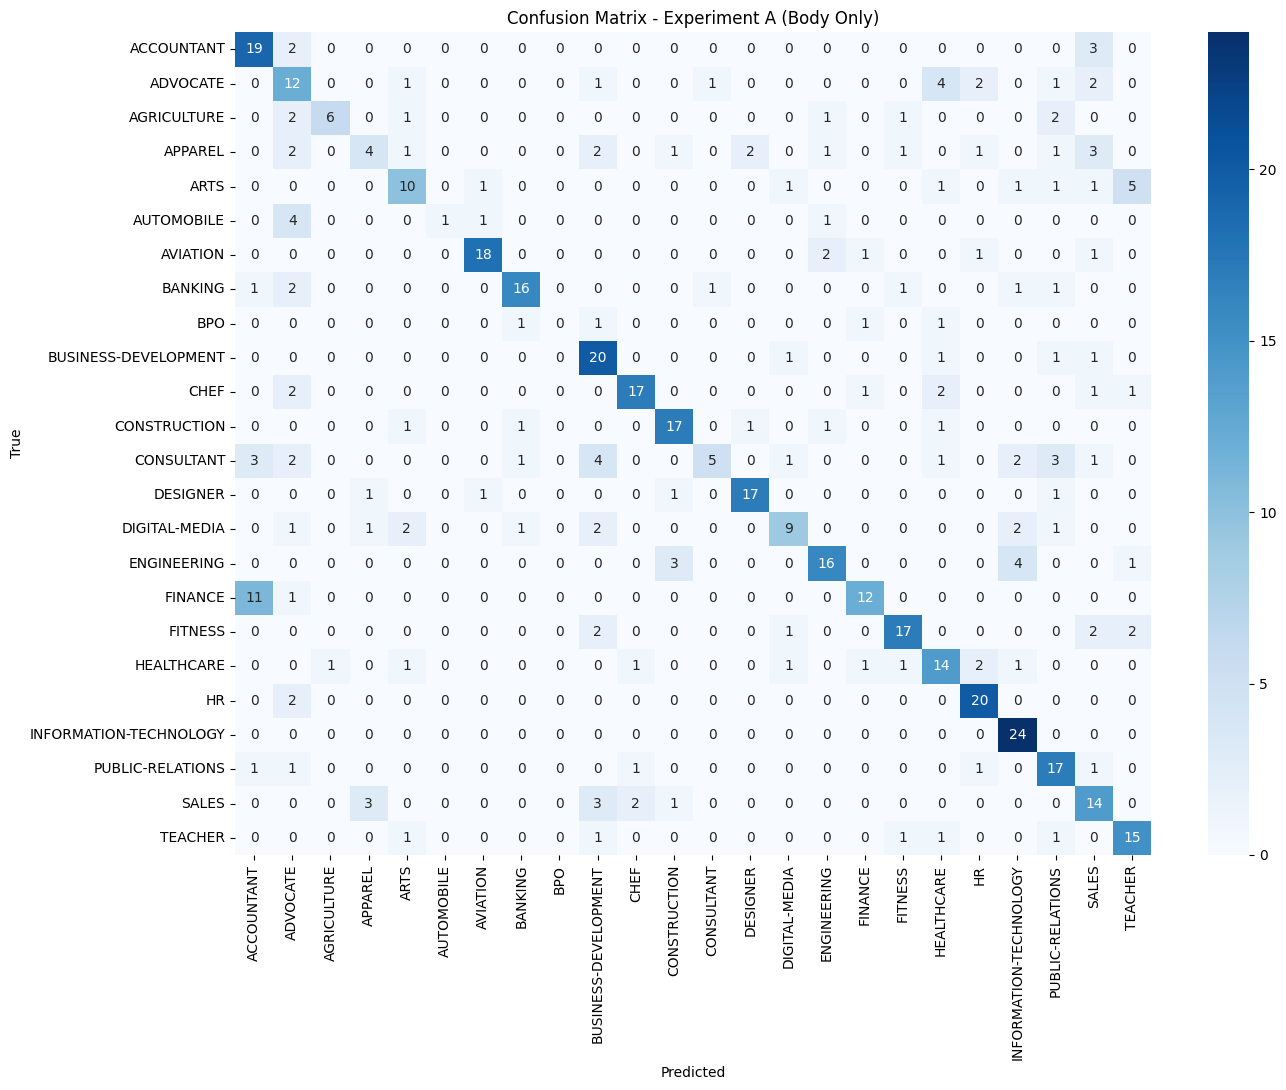

In [3]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = sorted(y.unique())
cm = confusion_matrix(y.loc[idx_test], pred_body, labels=labels)

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - Experiment A (Body Only)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [2]:
import re, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42

PKL = Path("/content/cv_skills.pkl")
if not PKL.exists():
    from google.colab import drive
    drive.mount("/content/drive")
    PKL = Path("/content/drive/MyDrive/cv_skills.pkl")

parsed = pd.read_pickle(PKL)
print("Loaded:", PKL, "| shape:", parsed.shape)

needed = ["category", "title", "body", "skills_listed", "skills_in_text"]
print("Missing columns:", [c for c in needed if c not in parsed.columns])

y = parsed["category"]
idx_train, idx_test = train_test_split(
    parsed.index, test_size=0.2, stratify=y, random_state=SEED
)

vec = TfidfVectorizer(sublinear_tf=True, min_df=3, ngram_range=(1, 2),
                      max_features=50000, stop_words="english")
Xtr = vec.fit_transform(parsed["body"].loc[idx_train])
Xte = vec.transform(parsed["body"].loc[idx_test])

clf = LogisticRegression(max_iter=2000, C=10).fit(Xtr, y.loc[idx_train])
pred_body = clf.predict(Xte)

acc = accuracy_score(y.loc[idx_test], pred_body)
f1 = f1_score(y.loc[idx_test], pred_body, average="macro")
print(f"A) body only (restored)  accuracy = {acc:.3f} | macro-F1 = {f1:.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: /content/drive/MyDrive/cv_skills.pkl | shape: (2481, 15)
Missing columns: []
A) body only (restored)  accuracy = 0.644 | macro-F1 = 0.594


## Part 12: Cross-Validation (5 امتحانات بدل امتحان واحد)

بدل تقسيم واحد 80/20، هنقسّم الداتا لـ 5 أجزاء. كل مرة جزء مختلف هو الاختبار والباقي تدريب، وبناخد المتوسط.

هنقارن موديلين:
1. Logistic Regression العادي
2. Logistic Regression بأوزان متوازنة (`class_weight='balanced'`) عشان الفئات الصغيرة زي BPO و AUTOMOBILE

In [4]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_enc = le.fit_transform(y)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_tfidf(max_features):
    return TfidfVectorizer(
        sublinear_tf=True, min_df=3, ngram_range=(1, 2),
        max_features=max_features, stop_words="english",
    )


models = {
    "LogReg": Pipeline([
        ("tfidf", make_tfidf(50000)),
        ("clf", LogisticRegression(max_iter=2000, C=10)),
    ]),
    "LogReg (balanced)": Pipeline([
        ("tfidf", make_tfidf(50000)),
        ("clf", LogisticRegression(max_iter=2000, C=10, class_weight="balanced")),
    ]),
}

cv_rows = []


def run_cv(name):
    t0 = time.time()
    s = cross_validate(models[name], parsed["body"], y_enc, cv=skf,
                       scoring=["accuracy", "f1_macro"], n_jobs=1)
    row = {
        "model": name,
        "accuracy": s["test_accuracy"].mean(), "acc_std": s["test_accuracy"].std(),
        "macro_F1": s["test_f1_macro"].mean(), "f1_std": s["test_f1_macro"].std(),
        "seconds": time.time() - t0,
    }
    cv_rows.append(row)
    print(f"{name:20s} accuracy = {row['accuracy']:.3f} ± {row['acc_std']:.3f} | "
          f"macro-F1 = {row['macro_F1']:.3f} ± {row['f1_std']:.3f} | {row['seconds']:.0f}s")

In [5]:
run_cv("LogReg")
run_cv("LogReg (balanced)")

LogReg               accuracy = 0.639 ± 0.014 | macro-F1 = 0.583 ± 0.011 | 165s
LogReg (balanced)    accuracy = 0.644 ± 0.016 | macro-F1 = 0.601 ± 0.012 | 132s


In [6]:
pd.DataFrame(cv_rows).set_index("model").round(3)

,accuracy,acc_std,macro_F1,f1_std,seconds
model,,,,,
LogReg,0.639,0.014,0.583,0.011,164.630
LogReg (balanced),0.644,0.016,0.601,0.012,132.396


## Part 13: Multi-Field Model (Title + Body + Skills as separate blocks)

اكتشفنا إن العنوان لوحده أحسن من النص كله، لأنه بيدوب لما بنلصقه فيه.
الحل: كل حقل ككتلة TF-IDF منفصلة بوزن متساوي، ونقارن بـ Cross-Validation:
1. title + body (منفصلين)
2. title + body + skills (المهارات المستخرجة كحقل تالت)

In [7]:
from sklearn.compose import ColumnTransformer

skills_text = (parsed["skills_listed"] + parsed["skills_in_text"]).apply(
    lambda lst: " ".join(s.replace(" ", "_") for s in lst)
)

X_all = pd.DataFrame({
    "title": parsed["title"],
    "body": parsed["body"],
    "skills": skills_text,
})


def make_multifield(use_skills):
    blocks = [
        ("title", TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2), "title"),
        ("body", make_tfidf(50000), "body"),
    ]
    if use_skills:
        blocks.append(
            ("skills", TfidfVectorizer(sublinear_tf=True, min_df=3, token_pattern=r"\S+"), "skills")
        )
    return Pipeline([
        ("features", ColumnTransformer(blocks)),
        ("clf", LogisticRegression(max_iter=2000, C=10)),
    ])


def run_cv_on(name, pipe, X):
    t0 = time.time()
    s = cross_validate(pipe, X, y_enc, cv=skf,
                       scoring=["accuracy", "f1_macro"], n_jobs=1)
    row = {
        "model": name,
        "accuracy": s["test_accuracy"].mean(), "acc_std": s["test_accuracy"].std(),
        "macro_F1": s["test_f1_macro"].mean(), "f1_std": s["test_f1_macro"].std(),
        "seconds": time.time() - t0,
    }
    cv_rows.append(row)
    print(f"{name:32s} accuracy = {row['accuracy']:.3f} ± {row['acc_std']:.3f} | "
          f"macro-F1 = {row['macro_F1']:.3f} ± {row['f1_std']:.3f} | {row['seconds']:.0f}s")

In [8]:
run_cv_on("LogReg title+body (separate)", make_multifield(False), X_all)
run_cv_on("LogReg title+body+skills", make_multifield(True), X_all)

LogReg title+body (separate)     accuracy = 0.805 ± 0.007 | macro-F1 = 0.741 ± 0.012 | 133s
LogReg title+body+skills         accuracy = 0.809 ± 0.007 | macro-F1 = 0.742 ± 0.012 | 108s


In [9]:
pd.DataFrame(cv_rows).set_index("model").round(3)

,accuracy,acc_std,macro_F1,f1_std,seconds
model,,,,,
LogReg,0.639,0.014,0.583,0.011,164.630
LogReg (balanced),0.644,0.016,0.601,0.012,132.396
LogReg title+body (separate),0.805,0.007,0.741,0.012,132.596
LogReg title+body+skills,0.809,0.007,0.742,0.012,107.725


In [10]:
import joblib
from collections import Counter
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

best = make_multifield(False)

oof = cross_val_predict(best, X_all, y_enc, cv=skf, n_jobs=1)
oof_names = le.inverse_transform(oof)

rep = pd.DataFrame(classification_report(y, oof_names, output_dict=True)).T
rep = rep.drop(index=["accuracy", "macro avg", "weighted avg"])

print("Weakest 8 categories (out-of-fold, all CVs):")
print(rep.sort_values("f1-score")[["precision", "recall", "f1-score", "support"]].head(8).round(2))

pairs = Counter((t, p) for t, p in zip(y, oof_names) if t != p)
print("\nMost common confusions (true -> predicted):")
for (t, p), n in pairs.most_common(8):
    print(f"  {t} -> {p}: {n}")

Weakest 8 categories (out-of-fold, all CVs):
             precision  recall  f1-score  support
BPO               0.25    0.05      0.08     22.0
AUTOMOBILE        0.22    0.06      0.09     36.0
AGRICULTURE       0.70    0.30      0.42     63.0
ARTS              0.49    0.50      0.49    103.0
APPAREL           0.51    0.55      0.53     97.0
FITNESS           0.61    0.63      0.62    117.0
BANKING           0.61    0.70      0.65    115.0
HEALTHCARE        0.63    0.74      0.68    115.0

Most common confusions (true -> predicted):
  ADVOCATE -> HEALTHCARE: 10
  FITNESS -> BANKING: 8
  AGRICULTURE -> BANKING: 8
  ADVOCATE -> FITNESS: 7
  FITNESS -> APPAREL: 7
  DIGITAL-MEDIA -> PUBLIC-RELATIONS: 7
  AUTOMOBILE -> BANKING: 7
  APPAREL -> ARTS: 7


In [11]:
best.fit(X_all, y_enc)

joblib.dump({"model": best, "label_encoder": le}, "/content/category_model.joblib")
!cp /content/category_model.joblib /content/drive/MyDrive/
print("Saved. Number of categories:", len(le.classes_))

Saved. Number of categories: 24


In [12]:
audit = pd.DataFrame({
    "true": y.values,
    "pred": oof_names,
    "title": parsed["title"].values,
})


def show_errors(true_cat, pred_cat, n=10):
    sub = audit[(audit["true"] == true_cat) & (audit["pred"] == pred_cat)]
    print(f"\n{true_cat} -> {pred_cat}  ({len(sub)} CVs)")
    for t in sub["title"].head(n):
        print("   -", t)


show_errors("AGRICULTURE", "BANKING")
show_errors("FITNESS", "BANKING")
show_errors("AUTOMOBILE", "BANKING")
show_errors("ADVOCATE", "HEALTHCARE")


AGRICULTURE -> BANKING  (8 CVs)
   - PROJECT ASSISTANT
   - PROGRAM ANALYST
   - VP, PRINCIPAL
   - ACCOUNTS PAYABLE AP - (CREDITORS) SUPERVISOR
   - FINANCIAL INSTITUTION EXAMINER
   - FINANCIAL SALES CONSULTANT
   - BUDGET ANALYST SERIES 0560
   - COMMITTEE MEMBER

FITNESS -> BANKING  (8 CVs)
   - BRANCH MANAGER
   - SERVICE REPRESENTATIVE
   - VICE PRESIDENT
   - ACCOUNT EXECUTIVE
   - SENIOR IMPLEMENTATION MANAGER
   - O
   - PROCUREMENT ANALYST
   - SENIOR SALES MANAGEMENT CONSULTANT

AUTOMOBILE -> BANKING  (7 CVs)
   - POLICY SERVICE SPECIALIST III
   - DEPUTY PRINCIPAL
   - TECHNICAL EDUCATIONS LANGUAGES
   - LEGAL ASSISTANT
   - CLINICAL AND DATA OPERATIONS SUPPORT ANALYST
   - SOFTWARE SUPPORT SPECIALIST
   - SENIOR ARCHITECT - MDM

ADVOCATE -> HEALTHCARE  (10 CVs)
   - MDS COORDINATOR
   - SENIOR APPLICATION SPECIALIST
   - NURSE CLINICIAN II ON MEDICAL/CARDIAC INTENSIVE CARE UNITS AND INTERVENTIONAL UNIT
   - RN / ASST. HEAD NURSE PRACTICE LEADER
   - PATIENT EXPERIENCE MAN

In [13]:
from sklearn.metrics import top_k_accuracy_score

proba = cross_val_predict(best, X_all, y_enc, cv=skf, n_jobs=1, method="predict_proba")

for k in (1, 3, 5):
    print(f"Top-{k} accuracy: {top_k_accuracy_score(y_enc, proba, k=k):.3f}")

Top-1 accuracy: 0.805
Top-3 accuracy: 0.891
Top-5 accuracy: 0.930


## Part 14: Years of Experience from Date Ranges

هنستخرج نطاقات التواريخ من قسم Experience (مثل `Dec 2013 to Current` و`09/2015 - 05/2016`) ونحسب:
1. إجمالي سنين الخبرة (بدون عدّ الفترات المتداخلة مرتين)
2. عدد الوظايف
3. سنة أول وظيفة

بعدين نفحص التوزيع، ومنه نحدد حدود Junior / Mid / Senior في الجزء الجاي.

In [14]:
MONTH = r"(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\.?"
MONTHS = {m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}


def date_pattern(p):
    return (rf"(?:(?P<{p}m>{MONTH})\s*,?\s*(?P<{p}y1>(?:19|20)\d{{2}})"
            rf"|(?P<{p}n>\d{{1,2}})\s*/\s*(?P<{p}y2>(?:19|20)\d{{2}})"
            rf"|(?P<{p}y3>(?:19|20)\d{{2}}))")


RANGE_RE = re.compile(
    rf"(?<![\w/]){date_pattern('s')}\s*(?:to|until|through|-|–|—)\s*"
    rf"(?:{date_pattern('e')}|(?P<cur>current|present|now|today|till date|to date|ongoing))",
    re.IGNORECASE,
)


def parse_date(p, g):
    year = g.get(p + "y1") or g.get(p + "y2") or g.get(p + "y3")
    if not year:
        return None
    if g.get(p + "m"):
        month = MONTHS[g[p + "m"][:3].lower()]
    elif g.get(p + "n"):
        month = int(g[p + "n"])
        if not 1 <= month <= 12:
            return None
    else:
        month = 6
    return int(year) * 12 + month


def extract_ranges(text, ref_ym):
    ranges = []
    for m in RANGE_RE.finditer(text):
        g = m.groupdict()
        start = parse_date("s", g)
        end = ref_ym if g.get("cur") else parse_date("e", g)
        if start is None or end is None:
            continue
        if start > ref_ym or end < start or end - start > 12 * 50:
            continue
        ranges.append((start, min(end, ref_ym)))
    return ranges


def total_months(ranges):
    if not ranges:
        return 0
    ranges = sorted(ranges)
    cur_s, cur_e = ranges[0]
    total = 0
    for s, e in ranges[1:]:
        if s <= cur_e:
            cur_e = max(cur_e, e)
        else:
            total += cur_e - cur_s
            cur_s, cur_e = s, e
    return total + (cur_e - cur_s)


def fmt_ym(v):
    return f"{(v - 1) // 12}-{(v - 1) % 12 + 1:02d}"

In [15]:
REF_YM = 2018 * 12 + 6

row = parsed[parsed["sec_experience"] != ""].sample(1, random_state=SEED).iloc[0]
ranges = extract_ranges(row["sec_experience"], REF_YM)

print("TITLE:", row["title"])
print("Detected date ranges:")
for s, e in sorted(ranges):
    print(f"  {fmt_ym(s)}  ->  {fmt_ym(e)}")
print(f"\nEstimated experience: {total_months(ranges) / 12:.1f} years")

print("\n--- Experience section (first 500 chars) ---")
print(row["sec_experience"][:500])

TITLE: ENGINEERING OFFICER
Detected date ranges:
  2011-06  ->  2011-07
  2012-06  ->  2012-07
  2013-06  ->  2014-06
  2014-07  ->  2015-06

Estimated experience: 2.1 years

--- Experience section (first 500 chars) ---
Engineering Officer 07/2014 to 06/2015 Spearheaded a team of electricians and technicians to carry out preventive maintenance of equipment of LPG bottling plant. Role also entailed
procurement of spares and materials and maintain inventory at plant. Major tasks involved:
Maintenance and calibration of equipment such as cylinder gas leak detectors, washer leak detectors, gas analyzers etc.
Upkeep of electrical panels and control systems.
Maintenance of drive units, compressors, LPG pumps etc.
Mod


In [16]:
end_years = []
for text in parsed["sec_experience"]:
    for m in RANGE_RE.finditer(text):
        g = m.groupdict()
        if g.get("cur"):
            continue
        y = g.get("ey1") or g.get("ey2") or g.get("ey3")
        if y and int(y) <= 2026:
            end_years.append(int(y))

REF_YEAR = int(np.percentile(end_years, 99))
REF_YM = REF_YEAR * 12 + 6
print("Explicit end dates found:", len(end_years))
print("Estimated snapshot year (99th percentile):", REF_YEAR)


def exp_features(text):
    r = extract_ranges(text, REF_YM)
    if not r:
        return pd.Series({"exp_years": np.nan, "n_jobs": 0, "first_job_year": np.nan})
    return pd.Series({
        "exp_years": round(total_months(r) / 12, 1),
        "n_jobs": len(r),
        "first_job_year": (min(s for s, _ in r) - 1) // 12,
    })


parsed = parsed.drop(columns=["exp_years", "n_jobs", "first_job_year"], errors="ignore")
parsed = parsed.join(parsed["sec_experience"].apply(exp_features))

print("\nCVs with no dates found:", parsed["exp_years"].isna().sum())
print(parsed["exp_years"].describe().round(1))
print("\nPercentiles:")
print(parsed["exp_years"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_string())

print("\nAvg experience by category (lowest 5 / highest 5):")
by_cat = parsed.groupby("category")["exp_years"].mean().sort_values().round(1)
print(pd.concat([by_cat.head(5), by_cat.tail(5)]).to_string())

Explicit end dates found: 9482
Estimated snapshot year (99th percentile): 2019

CVs with no dates found: 85
count    2396.0
mean       14.1
std         8.2
min         0.0
25%         8.0
50%        12.9
75%        19.0
max        45.4
Name: exp_years, dtype: float64

Percentiles:
0.10     4.5
0.25     8.0
0.50    12.9
0.75    19.0
0.90    25.4

Avg experience by category (lowest 5 / highest 5):
category
BPO                       10.6
SALES                     11.5
FITNESS                   11.6
DIGITAL-MEDIA             12.5
ADVOCATE                  13.2
FINANCE                   15.5
CONSTRUCTION              15.7
AUTOMOBILE                15.7
INFORMATION-TECHNOLOGY    15.8
BUSINESS-DEVELOPMENT      16.1


## Part 15: Rule-based Level Detection (Junior / Mid / Senior)

مفيش labels للمستوى في الداتا، فده **نظام قواعد** مش موديل متدرب:
- من سنين الخبرة: أقل من 2 = Junior، من 2 لأقل من 5 = Mid، 5 فأكتر = Senior
- كلمات العنوان بتعدّل المستوى بس لو السنين منطقية معاها
- لو مفيش تواريخ: من العنوان، وإلا Unknown

In [17]:
SENIOR_KW = re.compile(
    r"\b(senior|sr|lead|principal|head|director|vp|vice president|chief|president|ceo|cto|cfo|coo)\b", re.I
)
JUNIOR_KW = re.compile(
    r"\b(intern|internship|trainee|junior|jr|entry[- ]level|apprentice|graduate|student)\b", re.I
)


def years_level(y):
    if y < 2:
        return "Junior"
    if y < 5:
        return "Mid"
    return "Senior"


def assign_level(row):
    title, y = row["title"], row["exp_years"]
    if pd.isna(y):
        if SENIOR_KW.search(title):
            return "Senior"
        if JUNIOR_KW.search(title):
            return "Junior"
        return "Unknown"
    if JUNIOR_KW.search(title) and y < 4:
        return "Junior"
    if SENIOR_KW.search(title) and y >= 3:
        return "Senior"
    return years_level(y)


parsed["years_level"] = parsed["exp_years"].apply(lambda y: np.nan if pd.isna(y) else years_level(y))
parsed["level"] = parsed.apply(assign_level, axis=1)

print("Level distribution:")
print(parsed["level"].value_counts().to_string())

changed = (parsed["years_level"].notna() & (parsed["years_level"] != parsed["level"])).sum()
print("\nLevel changed by title keywords:", changed)
print("CVs with exp_years == 0:", (parsed["exp_years"] == 0).sum())

print("\nRandom sample (check by eye):")
print(parsed[["title", "exp_years", "level"]].sample(12, random_state=SEED).to_string(index=False))

Level distribution:
level
Senior     2133
Mid         191
Junior       86
Unknown      71

Level changed by title keywords: 16
CVs with exp_years == 0: 1

Random sample (check by eye):
                                           title  exp_years  level
INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)        7.6 Senior
                   BUSINESS DEVELOPMENT DIRECTOR       31.1 Senior
                              ENGINEERING INTERN        0.2 Junior
                      ENGINEERING LAB TECHNICIAN       14.0 Senior
                                  GUEST LECTURER        8.4 Senior
                    HEAD OF ACCOUNTS AND FINANCE       10.8 Senior
                  EMERGENCY DEPARTMENT PHYSICIAN       13.8 Senior
                                       SOUS CHEF       15.2 Senior
         MORTGAGE BANKING FORECLOSURE SPECIALIST       14.3 Senior
                CHILD PERFORMER WELFARE ADVOCATE        6.2 Senior
                                 SALES ASSOCIATE       12.8 Senior
           

In [18]:
parsed.to_pickle("/content/cv_skills.pkl")
!cp /content/cv_skills.pkl /content/drive/MyDrive/
print("Saved. Columns now:", len(parsed.columns))

Saved. Columns now: 20


## Part 16: Packaging the Pipeline as a Module (`cv_pipeline.py`)

هنجمّع كل الخطوات في ملف واحد:
PDF → نص → أقسام → مهارات → سنين خبرة → مستوى → أقرب 3 فئات

والمخرج JSON منظم جاهز للـ FastAPI. وبعدها نختبر إنه بيطلّع **نفس نتايج الـ notebook بالظبط**.

In [19]:
import json
from pathlib import Path

vocab_from_data = sorted(set().union(*parsed["skills_listed"], *parsed["skills_in_text"]))
Path("/content/skills_vocab.json").write_text(json.dumps(vocab_from_data, ensure_ascii=False), encoding="utf-8")
!cp /content/skills_vocab.json /content/drive/MyDrive/
print("Vocabulary size:", len(vocab_from_data))

Vocabulary size: 1048


In [20]:
%%writefile cv_pipeline.py
"""
cv_pipeline.py - CareerLens CV analysis pipeline.

CV (PDF or text)  ->  structured profile (a plain dict that can be returned as JSON).
Steps: extract text -> split sections -> skills -> years of experience -> level -> category.
"""
import datetime as dt
import json
import re
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

# ---------------------------------------------------------------- 1) text
EMAIL_RE = re.compile(r"[\w\.\-+]+@[\w\.\-]+\.\w+")
URL_RE = re.compile(r"(https?://\S+|www\.\S+)")
PHONE_RE = re.compile(r"(?<!\w)(\+?\d{1,3}[-.\s])?\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}(?!\w)")
LOC_RE = re.compile(r"\bCity\s*,\s*State\b")          # placeholders of the training dataset
COMP_RE = re.compile(r"Company Name\s*[－—–\-]*")      # (harmless on real CVs)
CTRL_RE = re.compile(r"[\x00-\x08\x0b-\x1f\x7f]")


def read_pdf(path):
    import pdfplumber
    with pdfplumber.open(path) as pdf:
        return "\n".join((page.extract_text() or "") for page in pdf.pages)


def clean_text(text):
    text = str(text)
    for rx in (URL_RE, EMAIL_RE, PHONE_RE, LOC_RE, COMP_RE, CTRL_RE):
        text = rx.sub(" ", text)
    text = text.replace("－", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\s+,", ",", text)
    text = re.sub(r"\s*\n\s*", "\n", text)
    return text.strip()


def extract_cv_text(pdf_path):
    from ftfy import fix_text
    return clean_text(fix_text(read_pdf(pdf_path)))


# ------------------------------------------------------------ 2) sections
SECTION_PATTERNS = {
    "summary": r"(professional |career |executive )?(summary|profile|objective)|career objective|summary of qualifications",
    "experience": r"((professional|work|relevant|related) )?(experience|history)|employment( history)?",
    "education": r"education( (and|&) (training|certifications?))?|(academic|educational) (background|qualifications)",
    "skills": r"((technical|key|core|computer) )?skills|skill highlights|highlights|(core )?(qualifications|competencies)|areas of expertise",
    "accomplishments": r"accomplishments|achievements|awards( and honors)?|honors|activities and honors",
    "additional": r"additional information|interests|affiliations|languages|certifications?|references",
}
SECTION_RES = {k: re.compile(rf"^(?:{v})$", re.I) for k, v in SECTION_PATTERNS.items()}


def detect_heading(line):
    s = re.sub(r"[^a-z& ]", " ", line.lower())
    s = re.sub(r"\s+", " ", s).strip()
    if not s or len(s.split()) > 5:
        return None
    for name, rx in SECTION_RES.items():
        if rx.match(s):
            return name
    return None


def split_sections(text):
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    title = ""
    if lines and detect_heading(lines[0]) is None:
        title = lines[0]
        lines = lines[1:]
    sections, current = {}, "header"
    for line in lines:
        heading = detect_heading(line)
        if heading:
            current = heading
            continue
        sections.setdefault(current, []).append(line)
    return title, {k: "\n".join(v) for k, v in sections.items()}


# --------------------------------------------------------------- 3) skills
def ngram_set(text, n_max=4):
    tokens = [t.strip(".-/&") for t in re.findall(r"[a-z0-9][a-z0-9+#./&-]*", text.lower())]
    tokens = [t for t in tokens if t]
    grams = set()
    for n in range(1, n_max + 1):
        for i in range(len(tokens) - n + 1):
            grams.add(" ".join(tokens[i:i + n]))
    return grams


def extract_skills(skills_section, body, vocab):
    listed = ngram_set(skills_section) & vocab
    elsewhere = (ngram_set(body) & vocab) - listed
    return sorted(listed), sorted(elsewhere)


# ----------------------------------------------------------- 4) experience
MONTH = r"(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\.?"
MONTHS = {m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}


def date_pattern(p):
    return (rf"(?:(?P<{p}m>{MONTH})\s*,?\s*(?P<{p}y1>(?:19|20)\d{{2}})"
            rf"|(?P<{p}n>\d{{1,2}})\s*/\s*(?P<{p}y2>(?:19|20)\d{{2}})"
            rf"|(?P<{p}y3>(?:19|20)\d{{2}}))")


RANGE_RE = re.compile(
    rf"(?<![\w/]){date_pattern('s')}\s*(?:to|until|through|-|–|—)\s*"
    rf"(?:{date_pattern('e')}|(?P<cur>current|present|now|today|till date|to date|ongoing))",
    re.IGNORECASE,
)


def parse_date(p, g):
    year = g.get(p + "y1") or g.get(p + "y2") or g.get(p + "y3")
    if not year:
        return None
    if g.get(p + "m"):
        month = MONTHS[g[p + "m"][:3].lower()]
    elif g.get(p + "n"):
        month = int(g[p + "n"])
        if not 1 <= month <= 12:
            return None
    else:
        month = 6
    return int(year) * 12 + month


def extract_ranges(text, ref_ym):
    ranges = []
    for m in RANGE_RE.finditer(text):
        g = m.groupdict()
        start = parse_date("s", g)
        end = ref_ym if g.get("cur") else parse_date("e", g)
        if start is None or end is None:
            continue
        if start > ref_ym or end < start or end - start > 12 * 50:
            continue
        ranges.append((start, min(end, ref_ym)))
    return ranges


def total_months(ranges):
    if not ranges:
        return 0
    ranges = sorted(ranges)
    cur_s, cur_e = ranges[0]
    total = 0
    for s, e in ranges[1:]:
        if s <= cur_e:
            cur_e = max(cur_e, e)
        else:
            total += cur_e - cur_s
            cur_s, cur_e = s, e
    return total + (cur_e - cur_s)


def experience_features(experience_section, ref_ym):
    ranges = extract_ranges(experience_section, ref_ym)
    if not ranges:
        return {"years": None, "jobs_found": 0, "first_job_year": None}
    return {
        "years": round(total_months(ranges) / 12, 1),
        "jobs_found": len(ranges),
        "first_job_year": int((min(s for s, _ in ranges) - 1) // 12),
    }


# ------------------------------------------------------------------ 5) level
SENIOR_KW = re.compile(
    r"\b(senior|sr|lead|principal|head|director|vp|vice president|chief|president|ceo|cto|cfo|coo)\b", re.I
)
JUNIOR_KW = re.compile(
    r"\b(intern|internship|trainee|junior|jr|entry[- ]level|apprentice|graduate|student)\b", re.I
)


def years_level(y):
    if y < 2:
        return "Junior"
    if y < 5:
        return "Mid"
    return "Senior"


def assign_level(title, years):
    if years is None:
        if SENIOR_KW.search(title):
            return "Senior", "title (no dates found)"
        if JUNIOR_KW.search(title):
            return "Junior", "title (no dates found)"
        return "Unknown", "no dates and no clear title keyword"
    if JUNIOR_KW.search(title) and years < 4:
        return "Junior", "title + years"
    if SENIOR_KW.search(title) and years >= 3:
        return "Senior", "title + years"
    return years_level(years), "years"


# -------------------------------------------------------------- 6) analyzer
class CVAnalyzer:
    def __init__(self, model_path, vocab_path):
        bundle = joblib.load(model_path)
        self.model = bundle["model"]
        self.label_encoder = bundle["label_encoder"]
        self.vocab = set(json.loads(Path(vocab_path).read_text(encoding="utf-8")))

    def analyze_text(self, text, ref_date=None, top_k=3):
        ref_date = ref_date or dt.date.today()
        ref_ym = ref_date.year * 12 + ref_date.month

        title, sections = split_sections(text)
        body = text.split("\n", 1)[1] if title and "\n" in text else text

        listed, elsewhere = extract_skills(sections.get("skills", ""), body, self.vocab)
        exp = experience_features(sections.get("experience", ""), ref_ym)
        level, basis = assign_level(title, exp["years"])

        X = pd.DataFrame({
            "title": [title],
            "body": [body],
            "skills": [" ".join(s.replace(" ", "_") for s in listed + elsewhere)],
        })
        proba = self.model.predict_proba(X)[0]
        names = self.label_encoder.inverse_transform(self.model.classes_)
        order = np.argsort(proba)[::-1][:top_k]

        return {
            "title": title,
            "categories": [
                {"category": str(names[i]), "probability": round(float(proba[i]), 3)} for i in order
            ],
            "experience": exp,
            "level": {"value": level, "basis": basis},
            "skills": {"listed": listed, "mentioned_elsewhere": elsewhere},
            "meta": {
                "n_words": len(text.split()),
                "sections_found": sorted(sections),
                "analysis_date": ref_date.isoformat(),
            },
        }

    def analyze_pdf(self, pdf_path, ref_date=None, top_k=3):
        return self.analyze_text(extract_cv_text(pdf_path), ref_date=ref_date, top_k=top_k)

Writing cv_pipeline.py


In [21]:
import importlib
import datetime as dt
import cv_pipeline

importlib.reload(cv_pipeline)

MODEL_PATH = "/content/category_model.joblib"
if not Path(MODEL_PATH).exists():
    MODEL_PATH = "/content/drive/MyDrive/category_model.joblib"

analyzer = cv_pipeline.CVAnalyzer(MODEL_PATH, "/content/skills_vocab.json")
REF_DATE = dt.date(2019, 6, 1)

# 1) شوفلي مخرجات حقيقية
for _, row in parsed.sample(2, random_state=SEED).iterrows():
    out = analyzer.analyze_text(row["text"], ref_date=REF_DATE)
    print("TRUE CATEGORY:", row["category"])
    print(json.dumps(out, indent=1, ensure_ascii=False)[:1800])
    print("-" * 60)

# 2) فحص التطابق مع الـ notebook على 60 CV
sample = parsed.sample(60, random_state=SEED)
mism_years = mism_level = 0
for _, row in sample.iterrows():
    out = analyzer.analyze_text(row["text"], ref_date=REF_DATE)
    y_mod = out["experience"]["years"]
    y_nb = None if pd.isna(row["exp_years"]) else row["exp_years"]
    if y_mod != y_nb:
        mism_years += 1
    if out["level"]["value"] != row["level"]:
        mism_level += 1
print(f"Years mismatches: {mism_years}/60 | Level mismatches: {mism_level}/60")

!cp /content/cv_pipeline.py /content/drive/MyDrive/

TRUE CATEGORY: INFORMATION-TECHNOLOGY
{
 "title": "INFORMATION TECHNOLOGY SPECIALIST(DISCOUNTPCFIX)",
 "categories": [
  {
   "category": "INFORMATION-TECHNOLOGY",
   "probability": 0.997
  },
  {
   "category": "AVIATION",
   "probability": 0.001
  },
  {
   "category": "HEALTHCARE",
   "probability": 0.0
  }
 ],
 "experience": {
  "years": 7.6,
  "jobs_found": 4,
  "first_job_year": 2011
 },
 "level": {
  "value": "Senior",
  "basis": "years"
 },
 "skills": {
  "listed": [
   "active directory",
   "apple",
   "critical thinking",
   "data management",
   "database",
   "database management",
   "hardware",
   "help desk",
   "lan",
   "leadership",
   "mechanical",
   "microsoft office",
   "ms office",
   "multitasking",
   "network",
   "network administration",
   "os",
   "project management",
   "quality",
   "quality control",
   "repairs",
   "reporting",
   "servers",
   "soldering",
   "supervision",
   "system administration",
   "telecommunications",
   "time management",